# 04 · Transformación e ingeniería de características

**Etapa 04 del pipeline** (transformación). Construye las variables derivadas, segmenta cada componente en
gamas y calcula el costo de referencia por componente, gama y perfil de home office. Produce el **dataset
final**.

| | Archivo |
| --- | --- |
| Entrada | `data/intermedio/03_homeoffice_integrado.csv` |
| Salida | `data/final/homeoffice_final.csv` (dataset final), `precios_por_gama.csv`, `perfiles_home_office.csv` |

**Técnicas del curso**: transformación logarítmica y escalamiento con puntuación Z (U4_L1, U4_T1); codificación
binaria con `get_dummies`, discretización por igual frecuencia con `qcut` y por agrupamiento con K-Means, y
construcción de atributos (U3_L7, U3_T5).

In [1]:
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import HTML
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

import comun
from comun import FINAL, INTERMEDIO, SEMILLA, escribir_csv, guardar_figura, registrar, registrar_balance, soles

comun.aplicar_estilo()
ho = pd.read_csv(INTERMEDIO / '03_homeoffice_integrado.csv', parse_dates=['fecha_extraccion'],
                 dtype={'id_oferta': 'string', 'id_catalogo': 'string'})
assert ho['id_oferta'].is_unique, 'Entrada inválida: id_oferta repetido (invariante de unicidad)'
N_ENTRADA = len(ho)
titulo = ho['titulo'].str.lower()
print(ho.shape)

(2714, 28)


## 1. Transformaciones (FR-016)

| Transformación | Por qué |
| --- | --- |
| `log_precio = log10(precio)` (ya calculada en el notebook 02) | El precio tiene cola derecha; en escala logarítmica los criterios estadísticos y los gráficos no quedan dominados por los productos de gama alta. |
| `precio_relativo`: puntuación Z de `log_precio` **dentro de cada componente** | Un mouse de S/ 300 y una laptop de S/ 9 000 no se comparan en soles; sí en cuántas desviaciones se alejan del precio típico de su componente. |
| Codificación binaria de `envio` con `get_dummies` | Convierte una categórica nominal en indicadores 0/1 que se pueden promediar y correlacionar (U3_T5: para nominales es la única opción). |

In [2]:
ho['precio_relativo'] = np.nan
for componente, indices in ho.groupby('componente').groups.items():
    ho.loc[indices, 'precio_relativo'] = StandardScaler().fit_transform(ho.loc[indices, ['log_precio']]).ravel().round(4)

envio_binario = pd.get_dummies(ho['envio'], prefix='envio', dtype=int)
print(envio_binario.sum().to_string())
ho['envio_gratis'] = ho['envio'].str.startswith('gratis')
ho['entrega_manana'] = ho['envio'].str.contains('mañana')
assert (ho['envio_gratis'] == envio_binario[['envio_gratis', 'envio_gratis mañana']].sum(axis=1).astype(bool)).all()
ho.groupby('componente')['precio_relativo'].agg(['mean', 'std']).round(3)

envio_gratis               374
envio_gratis mañana       2129
envio_mañana con costo      38
envio_no informado         173


,mean,std
componente,,
audifonos,-0.0,1.001
laptop,0.0,1.001
monitor,-0.0,1.001
mouse,-0.0,1.001
silla,0.0,1.001
teclado,-0.0,1.001


La media de `precio_relativo` es 0 y su desviación 1 en cada componente, como corresponde a una puntuación Z.
`envio_gratis` y `entrega_manana` resumen los cuatro indicadores binarios del envío en las dos preguntas que le
importan al comprador: ¿pago el envío? y ¿llega mañana?

## 2. Variables construidas (FR-017)

### Marca

Se busca en el título una lista de marcas presentes en los datos; gana la que aparece primero. Si no se reconoce
ninguna, la marca es `otra`.

In [3]:
MARCAS = ['apple', 'macbook', 'lenovo', 'hp', 'asus', 'acer', 'dell', 'msi', 'samsung', 'lg', 'xiaomi', 'huawei',
          'gigabyte', 'aoc', 'benq', 'viewsonic', 'philips', 'teros', 'logitech', 'redragon', 'razer', 'corsair',
          'hyperx', 'steelseries', 'sony', 'jbl', 'bose', 'sennheiser', 'qcy', 'soundcore', 'anker', 'edifier',
          'beyerdynamic', 'shure', 'klip xtreme', 'genius', 'microsoft', 'havit', 'aula', 'attack shark',
          'ergoclass', 'bonno', 'steelcase', 'sihoo', 'cougar', 'primus', 'chuwi', 'advance', 'kz', 'haylou',
          'soundpeats', 'baseus', 'hoco', 'cybertel', 'antryx', 'micronics', 'royal kludge', 'rk', 'keychron',
          'xtech', 'fantech', 'motospeed', 'flexispot', 'colamy', 'ugreen', 'realme', 'machenike', 'gravastar',
          'arzopa', 'tcl', 'atk', 'victus', 'thinkpad']
ALIAS = {'macbook': 'apple', 'victus': 'hp', 'thinkpad': 'lenovo', 'rk': 'royal kludge'}


def marca(texto):
    posiciones = {m: hallado.start() for m in MARCAS if (hallado := re.search(rf'\b{re.escape(m)}\b', texto))}
    if not posiciones:
        return 'otra'
    primera = min(posiciones, key=posiciones.get)
    return ALIAS.get(primera, primera)


ho['marca'] = titulo.map(marca)
cobertura_marca = ho.groupby('componente')['marca'].apply(lambda s: (s != 'otra').mean() * 100).round(1)
ho['tienda_de_marca'] = ho.apply(lambda f: f['marca'] != 'otra'
                                 and bool(re.search(rf'\b{re.escape(f["marca"])}\b', str(f['vendedor']).lower())),
                                 axis=1)
cobertura_marca.reindex(comun.ORDEN_COMPONENTES).to_frame('% con marca reconocida')

,% con marca reconocida
componente,
laptop,97.7
monitor,90.9
silla,33.6
teclado,80.0
mouse,79.6
audifonos,80.7


Las sillas de oficina tienen la menor cobertura: muchas se venden con nombres de modelo o sin marca. `otra` se
conserva como categoría explícita: no es un faltante.

### Especificaciones técnicas desde el título

Una especificación por componente, la que más influye en el precio de ese equipo. Se extraen con expresiones
regulares sobre el título y quedan nulas ("no aplica") en los demás componentes.

| Componente | Variable | Regla |
| --- | --- | --- |
| Laptop | `ram_gb`, `almacenamiento_gb` | "16 GB RAM", "RAM 16 GB", "8 GB DDR5"; "512 GB SSD", "1 TB"; si no hay etiqueta, una cantidad típica de RAM (4–64 GB) o de disco (128 GB–2 TB) |
| Monitor | `pulgadas` | número seguido de `"`, pulgadas o pulg.; si falta, un decimal o un entero de 15 a 57 que no sea Hz, ms ni sufijo de modelo |
| Teclado, mouse, audífonos | `inalambrico` | inalámbrico, wireless, Bluetooth, 2.4G, TWS |
| Silla | `ergonomica` | ergonómica |
| Todos | `es_gamer` | gamer o gaming |

In [4]:
def numero(serie):
    return pd.to_numeric(serie.str.replace(',', '.', regex=False), errors='coerce')


es = {c: ho['componente'].eq(c) for c in comun.ORDEN_COMPONENTES}

ram_etiquetada = titulo.str.extract(r'\b(\d{1,2})\s?gb\s?(?:de\s)?(?:ram|ddr\d?|lpddr\d?x?|memoria)|\bram\s?(\d{1,2})\s?gb',
                                    expand=True).bfill(axis=1)[0]
ram_tipica = titulo.str.extract(r'\b(4|8|12|16|18|24|32|36|48|64)\s?gb\b(?!\s?(?:ssd|hdd|emmc|de ssd|nvme))', expand=False)
ho['ram_gb'] = numero(ram_etiquetada.fillna(ram_tipica)).where(es['laptop']).astype('Int64')

disco = titulo.str.extract(r'\b(\d{3,4}|1|2)\s?(gb|tb)\s?(?:de\s)?(?:ssd|hdd|emmc|nvme|almacenamiento)'
                           r'|\bssd\s?(?:de\s)?(\d{3,4}|1|2)\s?(gb|tb)', expand=True)
disco_gb = numero(disco[0].fillna(disco[2])) * disco[1].fillna(disco[3]).map({'gb': 1, 'tb': 1024})
disco_tipico = titulo.str.extract(r'\b(128|256|512|1024)\s?gb\b|\b(1|2)\s?tb\b', expand=True)
disco_gb = disco_gb.fillna(numero(disco_tipico[0])).fillna(numero(disco_tipico[1]) * 1024)
ho['almacenamiento_gb'] = disco_gb.where(es['laptop']).astype('Int64')

pulgadas_marcadas = titulo.str.extract(r'\b(\d{2}(?:[.,]\d)?)\s?(?:"|”|\'\'|pulgadas|pulg\.?|p\b|inch|\'|plg)',
                                       expand=False)
pulgadas_decimal = titulo.str.extract(r'\b((?:1[3-9]|[2-4]\d|5[0-7])[.,]\d)\b', expand=False)
pulgadas_entero = titulo.str.extract(r'(?<![-.\d])\b(1[5-9]|[2-4]\d|5[0-7])\b'
                                     r'(?!\s?(?:hz|ms|w|gb|%|cm|mm|v|años|bits?)\b)', expand=False)
ho['pulgadas'] = numero(pulgadas_marcadas.fillna(pulgadas_decimal).fillna(pulgadas_entero)).where(es['monitor'])

perifericos_inalambricos = es['teclado'] | es['mouse'] | es['audifonos']
ho['inalambrico'] = (titulo.str.contains(r'inal[aá]mbric|wireless|bluetooth|\bbt\b|2[.,]4 ?g|\btws\b')
                     .where(perifericos_inalambricos).astype('boolean'))
ho['ergonomica'] = titulo.str.contains(r'ergon[oó]mic').where(es['silla']).astype('boolean')
ho['es_gamer'] = titulo.str.contains(r'gamer|gaming')

cobertura_specs = pd.DataFrame({
    'variable': ['ram_gb', 'almacenamiento_gb', 'pulgadas', 'inalambrico', 'ergonomica'],
    'componente': ['laptop', 'laptop', 'monitor', 'teclado, mouse, audífonos', 'silla'],
    '% de cobertura en su componente': [ho.loc[es['laptop'], 'ram_gb'].notna().mean() * 100,
                                        ho.loc[es['laptop'], 'almacenamiento_gb'].notna().mean() * 100,
                                        ho.loc[es['monitor'], 'pulgadas'].notna().mean() * 100,
                                        ho.loc[perifericos_inalambricos, 'inalambrico'].notna().mean() * 100,
                                        ho.loc[es['silla'], 'ergonomica'].notna().mean() * 100]}).round(1)
assert ho['ram_gb'].dropna().between(2, 128).all() and ho['pulgadas'].dropna().between(13, 57).all()
cobertura_specs

,variable,componente,% de cobertura en su componente
0,ram_gb,laptop,90.7
1,almacenamiento_gb,laptop,92.8
2,pulgadas,monitor,89.4
3,inalambrico,"teclado, mouse, audífonos",100.0
4,ergonomica,silla,100.0


### Promoción y reputación

- `descuento_inflado`: el descuento anunciado supera al calculado con los precios en más de 1,5 puntos. Permite
  medir cuántas promociones exageran el ahorro (notebook 01, inconsistencias).
- `tiene_descuento`, `descuento_pct`, `ofrece_cuotas`, `tiene_resenas` y `vendedor_visible` se construyeron en
  el notebook 02 al tratar los faltantes; `en_ambas_capturas` y `variacion_precio_pct`, en el 03.

In [5]:
ho['descuento_inflado'] = (ho['descuento_anunciado_pct'] - ho['descuento_pct']).gt(1.5).fillna(False)
print('Promociones con descuento inflado:', int(ho['descuento_inflado'].sum()), 'de', int(ho['tiene_descuento'].sum()))

Promociones con descuento inflado: 7 de 1522


## 3. Gamas por componente (FR-018)

Discretización por **igual frecuencia** (`qcut`, U3_L7): dentro de cada componente, el tercio más barato es la
gama **económica**, el central la **media** y el más caro la **alta**. Los cortes son los percentiles 33,3 y 66,7
del precio de cada componente; un precio exactamente igual al corte queda en la gama inferior.

Se elige igual frecuencia porque garantiza suficientes publicaciones en cada gama (unas 150) para que la mediana
sea estable; la discretización por igual ancho dejaría casi vacía la gama alta por la cola derecha del precio.

In [6]:
ho['gama'] = pd.Series(pd.NA, index=ho.index, dtype='string')
limites = []
for componente, indices in ho.groupby('componente').groups.items():
    gamas, cortes = pd.qcut(ho.loc[indices, 'precio'], q=3, labels=comun.ORDEN_GAMAS, retbins=True)
    ho.loc[indices, 'gama'] = gamas.astype('string')
    limites.append({'componente': componente, 'económica hasta': cortes[1], 'media hasta': cortes[2],
                    'alta hasta': cortes[3]})
ho['gama'] = pd.Categorical(ho['gama'], categories=comun.ORDEN_GAMAS, ordered=True)
tabla_limites = pd.DataFrame(limites).set_index('componente').reindex(comun.ORDEN_COMPONENTES).round(2)
tabla_limites

,económica hasta,media hasta,alta hasta
componente,,,
laptop,3589.00,6279.00,18499.0
monitor,553.59,1082.33,7999.0
silla,379.00,682.33,45499.0
teclado,159.00,300.00,1649.0
mouse,60.71,155.00,853.0
audifonos,99.00,249.00,3888.0


**Contraste: discretización por agrupamiento.** K-Means de una dimensión sobre `log_precio` (U3_L7) con tres
grupos ordenados por su centro. Si ambos métodos coinciden en la mayoría de publicaciones, los cortes por
terciles no son arbitrarios.

In [7]:
coincidencia = {}
for componente, indices in ho.groupby('componente').groups.items():
    modelo = KMeans(n_clusters=3, n_init=10, random_state=SEMILLA).fit(ho.loc[indices, ['log_precio']])
    orden = np.argsort(modelo.cluster_centers_.ravel())
    gama_kmeans = pd.Series(modelo.labels_, index=indices).map(dict(zip(orden, comun.ORDEN_GAMAS)))
    coincidencia[componente] = (gama_kmeans == ho.loc[indices, 'gama'].astype(str)).mean() * 100
pd.Series(coincidencia).reindex(comun.ORDEN_COMPONENTES).round(1).to_frame('% de coincidencia qcut vs K-Means')

,% de coincidencia qcut vs K-Means
laptop,78.3
monitor,72.7
silla,56.6
teclado,79.7
mouse,94.5
audifonos,77.5


**Validación con variables distintas del precio.** Si las gamas separan equipos realmente distintos, las
especificaciones deben subir de gama en gama.

In [8]:
validacion = pd.DataFrame({
    'laptop: RAM mediana (GB)': ho[es['laptop']].groupby('gama', observed=True)['ram_gb'].median(),
    'laptop: almacenamiento mediano (GB)': ho[es['laptop']].groupby('gama', observed=True)['almacenamiento_gb'].median(),
    'monitor: pulgadas medianas': ho[es['monitor']].groupby('gama', observed=True)['pulgadas'].median(),
    'periféricos: % inalámbricos': ho[perifericos_inalambricos].groupby('gama', observed=True)['inalambrico']
    .apply(lambda s: s.astype(float).mean() * 100),
    'silla: % ergonómicas': ho[es['silla']].groupby('gama', observed=True)['ergonomica']
    .apply(lambda s: s.astype(float).mean() * 100),
}).round(1)
validacion

,laptop: RAM mediana (GB),laptop: almacenamiento mediano (GB),monitor: pulgadas medianas,periféricos: % inalámbricos,silla: % ergonómicas
gama,,,,,
económica,16.0,512.0,24.0,57.9,34.2
media,16.0,512.0,27.0,57.0,49.0
alta,32.0,1024.0,27.0,56.7,57.3


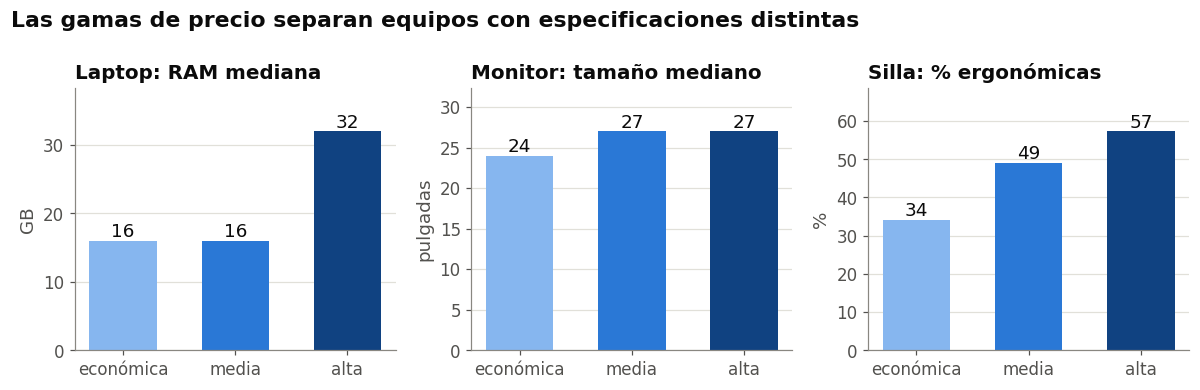

Lectura: En parte, y cada componente de forma distinta. La RAM mediana de las laptops es 16, 16 y 32 GB en las gamas económica, media y alta: la memoria distingue a la gama alta. El monitor mediano mide 24, 27 y 27 pulgadas: el tamaño distingue a la gama económica. Las sillas ergonómicas pasan de 34 % a 57 %. En cambio, la proporción de periféricos inalámbricos apenas cambia (57–58 %): la conexión inalámbrica no es lo que encarece un teclado, un mouse o unos audífonos.


In [9]:
fig, ejes = plt.subplots(1, 3, figsize=(11, 3.6))
pares = [('laptop: RAM mediana (GB)', 'Laptop: RAM mediana', 'GB'),
         ('monitor: pulgadas medianas', 'Monitor: tamaño mediano', 'pulgadas'),
         ('silla: % ergonómicas', 'Silla: % ergonómicas', '%')]
for ax, (columna, titulo_eje, unidad) in zip(ejes, pares):
    valores = validacion[columna]
    ax.bar(valores.index.astype(str), valores, color=[comun.COLOR_GAMA[g] for g in valores.index], width=0.6)
    for x, v in enumerate(valores):
        ax.text(x, v, f'{v:.0f}', ha='center', va='bottom', color=comun.TINTA)
    ax.set(title=titulo_eje, ylabel=unidad, ylim=(0, valores.max() * 1.2))
    ax.grid(axis='x', visible=False)
fig.suptitle('Las gamas de precio separan equipos con especificaciones distintas', x=0.01, ha='left',
             fontweight='bold')
fig.tight_layout()
ram_g = validacion['laptop: RAM mediana (GB)']
pulg_g = validacion['monitor: pulgadas medianas']
ergo_g = validacion['silla: % ergonómicas']
inal_g = validacion['periféricos: % inalámbricos']
guardar_figura(fig, 'f04_validacion_gamas',
               '¿Las gamas definidas por precio corresponden a equipos distintos?',
               f'En parte, y cada componente de forma distinta. La RAM mediana de las laptops es '
               f'{ram_g.iloc[0]:.0f}, {ram_g.iloc[1]:.0f} y {ram_g.iloc[2]:.0f} GB en las gamas económica, media y alta: '
               f'la memoria distingue a la gama alta. El monitor mediano mide {pulg_g.iloc[0]:.0f}, {pulg_g.iloc[1]:.0f} y '
               f'{pulg_g.iloc[2]:.0f} pulgadas: el tamaño distingue a la gama económica. Las sillas ergonómicas pasan de '
               f'{ergo_g.iloc[0]:.0f} % a {ergo_g.iloc[2]:.0f} %. En cambio, la proporción de periféricos inalámbricos '
               f'apenas cambia ({inal_g.min():.0f}–{inal_g.max():.0f} %): la conexión inalámbrica no es lo que '
               f'encarece un teclado, un mouse o unos audífonos.')

## 4. Costo por componente, gama y perfil (FR-020)

- **Por componente y gama**: mínimo, cuartiles, mediana y máximo del precio.
- **Por perfil de home office**: un componente de cada tipo en la misma gama. El valor central es la suma de las
  medianas; el rango es la suma de los cuartiles 1 y 3 de cada componente. No es un intervalo de confianza: es el
  rango de precios que cubre la mitad central de la oferta de cada componente, sumado.

In [10]:
precios_por_gama = (ho.groupby(['componente', 'gama'], observed=True)['precio']
                    .agg(n='size', precio_min='min', q1=lambda s: s.quantile(0.25), mediana='median',
                         q3=lambda s: s.quantile(0.75), precio_max='max').round(2).reset_index())
precios_por_gama['componente'] = pd.Categorical(precios_por_gama['componente'], comun.ORDEN_COMPONENTES, ordered=True)
precios_por_gama = precios_por_gama.sort_values(['componente', 'gama']).reset_index(drop=True)

PERFILES = {'económico': 'económica', 'medio': 'media', 'alto': 'alta'}
filas = []
for perfil, gama in PERFILES.items():
    g = precios_por_gama[precios_por_gama['gama'] == gama].set_index('componente')
    fila = {'perfil': perfil, 'costo_mediano': g['mediana'].sum(), 'costo_q1': g['q1'].sum(),
            'costo_q3': g['q3'].sum()}
    fila.update({f'mediana_{c}': g.loc[c, 'mediana'] for c in comun.ORDEN_COMPONENTES})
    filas.append(fila)
perfiles = pd.DataFrame(filas).round(2)

referencia = ho.groupby('componente')['precio'].median()
costo_sin_gama = referencia.sum()
HTML(perfiles[['perfil', 'costo_mediano', 'costo_q1', 'costo_q3']].style.set_uuid('perfiles').format(
    {c: lambda v: soles(v, 2) for c in ['costo_mediano', 'costo_q1', 'costo_q3']}).to_html())

,perfil,costo_mediano,costo_q1,costo_q3
0,económico,"S/ 3 644,11","S/ 2 812,30","S/ 4 201,99"
1,medio,"S/ 6 331,50","S/ 5 490,54","S/ 7 373,38"
2,alto,"S/ 12 322,58","S/ 10 463,63","S/ 16 238,76"


In [11]:
print(f'Suma de medianas sin distinguir gamas (método de la Parte I, con datos limpios): {soles(costo_sin_gama, 2)}')
print(f'Parte I, con accesorios, combos y duplicados por catálogo: {soles(6335.44, 2)}')
precios_por_gama

Suma de medianas sin distinguir gamas (método de la Parte I, con datos limpios): S/ 6 325,50
Parte I, con accesorios, combos y duplicados por catálogo: S/ 6 335,44


,componente,gama,n,precio_min,q1,mediana,q3,precio_max
0,laptop,económica,159,879.00,2144.00,2800.00,3157.50,3589.00
1,laptop,media,158,3590.00,4006.75,4599.00,5298.00,6279.00
2,laptop,alta,158,6372.00,7455.75,8315.00,9944.75,18499.00
3,monitor,económica,161,135.90,351.00,407.88,469.93,549.00
4,monitor,media,161,555.89,650.00,750.00,899.00,1080.00
5,monitor,alta,161,1087.00,1271.00,1679.00,2840.00,7999.00
6,silla,económica,158,99.99,187.00,251.38,314.80,379.00
7,silla,media,155,382.18,429.00,500.00,587.00,682.00
8,silla,alta,157,682.50,792.50,980.00,1361.00,45499.00
9,teclado,económica,116,17.00,39.00,75.95,125.16,159.00


## 5. Inventario de variables derivadas (FR-019)

Cada variable derivada con su regla, su cobertura y el uso que tiene en el análisis (notebook 05).

In [12]:
DERIVADAS = {
    'log_precio': ('log10 del precio', 'escala de todos los gráficos de precio'),
    'precio_relativo': ('puntuación Z de log_precio dentro del componente', 'comparar caro/barato entre componentes'),
    'gama': ('terciles de precio por componente', 'costo por gama y por perfil'),
    'atipico_precio': ('IQR o |z| > 3 sobre log_precio, conservado', 'separar productos extremos en el análisis'),
    'tiene_descuento': ('precio anterior presente y mayor que el precio', 'efecto de las promociones'),
    'descuento_pct': ('(precio anterior − precio) / precio anterior; 0 sin promoción', 'profundidad de las promociones'),
    'descuento_inflado': ('anunciado − calculado > 1,5 puntos', 'promociones que exageran el ahorro'),
    'ofrece_cuotas': ('texto de cuotas presente', 'peso del financiamiento'),
    'tiene_resenas': ('calificación o vendidos presentes', 'sesgo de reputación'),
    'vendidos_min': ('"+N vendidos" → N (cota inferior)', 'popularidad frente a precio'),
    'envio_gratis': ('envío empieza con "gratis"', 'condiciones de envío'),
    'entrega_manana': ('envío contiene "mañana"', 'condiciones de envío'),
    'vendedor_visible': ('nombre de tienda presente', 'tipo de vendedor'),
    'tienda_de_marca': ('el vendedor contiene la marca del producto', 'tienda oficial frente a revendedor'),
    'marca': ('primera marca reconocida en el título', 'prima de marca'),
    'es_gamer': ('"gamer" o "gaming" en el título', 'sobreprecio gamer'),
    'es_publicidad': ('URL de anuncio patrocinado (notebook 01)', 'anuncios frente a resultados orgánicos'),
    'ram_gb': ('GB de RAM en el título (laptop)', 'precio frente a especificación'),
    'almacenamiento_gb': ('GB de disco en el título (laptop)', 'precio frente a especificación'),
    'pulgadas': ('tamaño en el título (monitor)', 'precio frente a especificación'),
    'inalambrico': ('inalámbrico/Bluetooth en el título (periféricos)', 'sobreprecio inalámbrico'),
    'ergonomica': ('"ergonómica" en el título (silla)', 'sobreprecio ergonómico'),
    'en_ambas_capturas': ('la oferta figura el 13/09 y el 15/09 (notebook 03)', 'estabilidad de precios'),
    'variacion_precio_pct': ('cambio de precio entre capturas (notebook 03)', 'estabilidad de precios'),
}
inventario = pd.DataFrame([{'variable': v, 'regla': r, 'uso en el análisis': u,
                            'cobertura (%)': round(ho[v].notna().mean() * 100, 1)} for v, (r, u) in DERIVADAS.items()])
assert len(inventario) >= 10, 'SC-006: se requieren al menos 10 variables derivadas'
inventario

,variable,regla,uso en el análisis,cobertura (%)
0,log_precio,log10 del precio,escala de todos los gráficos de precio,100.0
1,precio_relativo,puntuación Z de log_precio dentro del componente,comparar caro/barato entre componentes,100.0
2,gama,terciles de precio por componente,costo por gama y por perfil,100.0
3,atipico_precio,"IQR o |z| > 3 sobre log_precio, conservado",separar productos extremos en el análisis,100.0
4,tiene_descuento,precio anterior presente y mayor que el precio,efecto de las promociones,100.0
5,descuento_pct,(precio anterior − precio) / precio anterior; ...,profundidad de las promociones,100.0
6,descuento_inflado,"anunciado − calculado > 1,5 puntos",promociones que exageran el ahorro,100.0
7,ofrece_cuotas,texto de cuotas presente,peso del financiamiento,100.0
8,tiene_resenas,calificación o vendidos presentes,sesgo de reputación,100.0
9,vendidos_min,"""+N vendidos"" → N (cota inferior)",popularidad frente a precio,36.8


La cobertura baja de `ram_gb`, `almacenamiento_gb`, `pulgadas`, `inalambrico` y `ergonomica` es por diseño:
solo aplican a un componente. Dentro de su componente la cobertura está en la tabla de la sección 2.

## 6. Dataset final y verificación

In [13]:
COLUMNAS_FINALES = ['id_oferta', 'id_catalogo', 'componente', 'titulo', 'marca', 'precio', 'log_precio',
                    'precio_relativo', 'gama', 'atipico_precio', 'precio_anterior', 'tiene_descuento', 'descuento_pct',
                    'descuento_anunciado_pct', 'descuento_inflado', 'ofrece_cuotas', 'numero_cuotas', 'monto_cuota',
                    'tiene_resenas', 'calificacion', 'vendidos_min', 'envio', 'envio_gratis', 'entrega_manana',
                    'vendedor', 'vendedor_visible', 'tienda_de_marca', 'es_publicidad', 'es_gamer', 'ram_gb',
                    'almacenamiento_gb', 'pulgadas', 'inalambrico', 'ergonomica', 'en_ambas_capturas', 'precio_13_09',
                    'variacion_precio_pct', 'pagina', 'posicion_pagina', 'url_publicacion', 'fecha_extraccion']
final = ho[COLUMNAS_FINALES].sort_values(['componente', 'precio', 'id_oferta']).reset_index(drop=True)

# Columnas que pueden superar 10 % de nulos y por qué (SC-005); cualquier otra debe quedar por debajo.
NULOS_JUSTIFICADOS = {
    'precio_anterior': 'estructural: sin promoción', 'descuento_anunciado_pct': 'estructural: sin promoción',
    'calificacion': 'MAR: la tarjeta no muestra reseñas', 'vendidos_min': 'MAR: la tarjeta no muestra reseñas',
    'ram_gb': 'no aplica: solo laptops', 'almacenamiento_gb': 'no aplica: solo laptops',
    'pulgadas': 'no aplica: solo monitores', 'inalambrico': 'no aplica: solo periféricos',
    'ergonomica': 'no aplica: solo sillas', 'precio_13_09': 'solo ofertas presentes en ambas capturas',
    'variacion_precio_pct': 'solo ofertas presentes en ambas capturas',
}
nulos = final.isna().mean() * 100
sin_justificar = nulos[(nulos > 10) & ~nulos.index.isin(list(NULOS_JUSTIFICADOS))]
assert sin_justificar.empty, f'Columnas con más de 10 % de nulos sin justificar: {sin_justificar.to_dict()}'
assert final['id_oferta'].is_unique and final['gama'].notna().all(), 'cada publicación pertenece a exactamente una `gama`'
assert final['precio'].gt(0).all()

# SC-004: ofertas válidas = únicas que son una unidad del componente buscado (sin accesorios ni combos).
limpieza = comun.leer_metricas()['limpieza']
conservadas = len(final) / limpieza['ofertas_unicas'] * 100
conservadas_vs_unicas = len(final) / (limpieza['ofertas_unicas'] + sum(limpieza['ajenas'].values())) * 100
assert conservadas >= 95, f'SC-004: se conserva {conservadas:.2f} % de las ofertas válidas'
registrar_balance('04_homeoffice', N_ENTRADA, len(final))

escribir_csv(final, FINAL / 'homeoffice_final.csv')
escribir_csv(precios_por_gama, FINAL / 'precios_por_gama.csv')
escribir_csv(perfiles, FINAL / 'perfiles_home_office.csv')

registrar('caracteristicas',
          variables_derivadas=len(inventario), cobertura_marca=cobertura_marca.to_dict(),
          cobertura_specs=dict(zip(cobertura_specs['variable'], cobertura_specs['% de cobertura en su componente'])),
          descuento_inflado=int(final['descuento_inflado'].sum()), con_descuento=int(final['tiene_descuento'].sum()),
          coincidencia_qcut_kmeans=coincidencia, limites_gama=tabla_limites.to_dict(orient='index'),
          validacion_gamas=validacion.to_dict(orient='index'))
registrar('dataset_final', filas=len(final), columnas=final.shape[1], conservadas_pct=conservadas,
          conservadas_vs_todas_las_unicas_pct=conservadas_vs_unicas,
          max_nulos_no_justificado=float(nulos[~nulos.index.isin(list(NULOS_JUSTIFICADOS))].max()),
          nulos=nulos.round(2).to_dict(), nulos_justificados=NULOS_JUSTIFICADOS)
registrar('costos', perfiles=perfiles.set_index('perfil')[['costo_mediano', 'costo_q1', 'costo_q3']].to_dict(orient='index'),
          suma_medianas_sin_gama=costo_sin_gama, suma_medianas_parte1=6335.44,
          medianas_por_componente=referencia.to_dict())
print('homeoffice_final.csv:', final.shape)
print(f'Conserva {conservadas:.2f} % de las ofertas válidas (únicas que son el componente) y '
      f'{conservadas_vs_unicas:.1f} % de todas las ofertas únicas, incluidos accesorios y combos.')

homeoffice_final.csv: (2714, 41)
Conserva 99.96 % de las ofertas válidas (únicas que son el componente) y 93.8 % de todas las ofertas únicas, incluidos accesorios y combos.


## Resultado de la etapa

- El dataset final tiene una fila por oferta y todas las variables de `data-model.md`; las columnas con más de
  10 % de nulos son justamente las que no aplican al componente o cuyo faltante es estructural o MAR.
- Se construyeron más de 20 variables derivadas, cada una con su regla, cobertura y uso.
- Las gamas por terciles coinciden en buena medida con la discretización por K-Means y las especificaciones las
  respaldan de forma distinta en cada componente; la conexión inalámbrica no varía entre gamas.
- El costo de referencia se calcula por componente, gama y perfil.